In [1]:
!pip install nltk scikit-learn textblob wordcloud matplotlib tensorflow

In [2]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

# Download required NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# Paragraph about Artificial Intelligence
text = """Artificial intelligence is transforming modern technology.
It helps computers learn from data and solve complex problems.
AI is used in healthcare, education, transportation, and business.
Machine learning enables systems to improve their performance over time.
I believe artificial intelligence can make our lives easier and more productive."""

# 1. Convert to lowercase and remove punctuation
clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("Cleaned Text:\n", clean_text)

# 2. Tokenize into words and sentences
words = word_tokenize(text)
sentences = sent_tokenize(text)

print("\nWord Tokens:\n", words)
print("\nSentence Tokens:\n", sentences)

# 3. Compare split() and word_tokenize()
print("\nUsing split():\n", text.split())
print("\nUsing word_tokenize():\n", word_tokenize(text))

# 4. Remove stopwords
stop_words = set(stopwords.words('english'))

filtered_words = [
    word for word in word_tokenize(clean_text)
    if word.isalpha() and word not in stop_words
]

print("\nWords after Stopword Removal:\n", filtered_words)

# 5. Word frequency distribution
frequency = FreqDist(filtered_words)
print("\nWord Frequency Distribution:")
print(frequency.most_common())

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...


Cleaned Text:
 artificial intelligence is transforming modern technology
it helps computers learn from data and solve complex problems
ai is used in healthcare education transportation and business
machine learning enables systems to improve their performance over time
i believe artificial intelligence can make our lives easier and more productive

Word Tokens:
 ['Artificial', 'intelligence', 'is', 'transforming', 'modern', 'technology', '.', 'It', 'helps', 'computers', 'learn', 'from', 'data', 'and', 'solve', 'complex', 'problems', '.', 'AI', 'is', 'used', 'in', 'healthcare', ',', 'education', ',', 'transportation', ',', 'and', 'business', '.', 'Machine', 'learning', 'enables', 'systems', 'to', 'improve', 'their', 'performance', 'over', 'time', '.', 'I', 'believe', 'artificial', 'intelligence', 'can', 'make', 'our', 'lives', 'easier', 'and', 'more', 'productive', '.']

Sentence Tokens:
 ['Artificial intelligence is transforming modern technology.', 'It helps computers learn from data 

[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [3]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')

text = """Artificial intelligence is transforming modern technology.
It helps computers learn from data and solve complex problems.
AI is used in healthcare, education, transportation, and business.
Machine learning enables systems to improve their performance over time.
I believe artificial intelligence can make our lives easier and more productive."""

# 1. Extract words containing only alphabets
words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("Alphabetic Words:\n", words)

# 2. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]
print("\nAfter Stopword Removal:\n", filtered_words)

# 3. Stemming
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in filtered_words]
print("\nStemmed Words:\n", stemmed_words)

# 4. Lemmatization
lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(w) for w in filtered_words]
print("\nLemmatized Words:\n", lemmatized_words)

# 5. Compare outputs
print("\nComparison:")
for original, stem, lemma in zip(
    filtered_words, stemmed_words, lemmatized_words
):
    print(original, "-> Stem:", stem, "| Lemma:", lemma)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Alphabetic Words:
 ['artificial', 'intelligence', 'is', 'transforming', 'modern', 'technology', 'it', 'helps', 'computers', 'learn', 'from', 'data', 'and', 'solve', 'complex', 'problems', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'transportation', 'and', 'business', 'machine', 'learning', 'enables', 'systems', 'to', 'improve', 'their', 'performance', 'over', 'time', 'i', 'believe', 'artificial', 'intelligence', 'can', 'make', 'our', 'lives', 'easier', 'and', 'more', 'productive']

After Stopword Removal:
 ['artificial', 'intelligence', 'transforming', 'modern', 'technology', 'helps', 'computers', 'learn', 'data', 'solve', 'complex', 'problems', 'ai', 'used', 'healthcare', 'education', 'transportation', 'business', 'machine', 'learning', 'enables', 'systems', 'improve', 'performance', 'time', 'believe', 'artificial', 'intelligence', 'make', 'lives', 'easier', 'productive']

Stemmed Words:
 ['artifici', 'intellig', 'transform', 'modern', 'technolog', 'help', 'comput', 'learn',

In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Three short texts
texts = [
    "Artificial intelligence improves healthcare and medical diagnosis.",
    "Blockchain provides secure transactions and decentralized records.",
    "Machine learning helps artificial intelligence analyze data."
]

# 1. Bag of Words
count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)

print("Bag of Words Vocabulary:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words Matrix:")
print(bow_matrix.toarray())

# 2. TF-IDF
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray().round(3))

# 3. Top 3 keywords from each text
feature_names = tfidf_vectorizer.get_feature_names_out()

print("\nTop 3 Keywords for Each Text:")
for i, text in enumerate(texts):
    scores = tfidf_matrix[i].toarray().flatten()
    top_indices = scores.argsort()[-3:][::-1]

    keywords = [
        (feature_names[j], round(scores[j], 3))
        for j in top_indices
    ]

    print(f"Text {i + 1}: {keywords}")

Bag of Words Vocabulary:
['analyze' 'and' 'artificial' 'blockchain' 'data' 'decentralized'
 'diagnosis' 'healthcare' 'helps' 'improves' 'intelligence' 'learning'
 'machine' 'medical' 'provides' 'records' 'secure' 'transactions']

Bag of Words Matrix:
[[0 1 1 0 0 0 1 1 0 1 1 0 0 1 0 0 0 0]
 [0 1 0 1 0 1 0 0 0 0 0 0 0 0 1 1 1 1]
 [1 0 1 0 1 0 0 0 1 0 1 1 1 0 0 0 0 0]]

TF-IDF Matrix:
[[0.    0.318 0.318 0.    0.    0.    0.418 0.418 0.    0.418 0.318 0.
  0.    0.418 0.    0.    0.    0.   ]
 [0.    0.297 0.    0.39  0.    0.39  0.    0.    0.    0.    0.    0.
  0.    0.    0.39  0.39  0.39  0.39 ]
 [0.403 0.    0.307 0.    0.403 0.    0.    0.    0.403 0.    0.307 0.403
  0.403 0.    0.    0.    0.    0.   ]]

Top 3 Keywords for Each Text:
Text 1: [('improves', np.float64(0.418)), ('medical', np.float64(0.418)), ('diagnosis', np.float64(0.418))]
Text 2: [('transactions', np.float64(0.39)), ('secure', np.float64(0.39)), ('records', np.float64(0.39))]
Text 3: [('learning', np.float64(0.4

In [5]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

# Two technology descriptions (five lines each)
ai_text = """Artificial intelligence allows computers to learn from data.
AI systems recognize patterns and make predictions.
Machine learning is an important part of AI.
AI is used in healthcare, education, and robotics.
Intelligent systems can automate complex tasks."""

blockchain_text = """Blockchain stores information in distributed digital records.
It supports secure and transparent transactions.
Cryptocurrency is one application of blockchain.
Blockchain networks use cryptographic techniques.
Distributed records can improve data integrity."""

# 1. Preprocess and tokenize
stop_words = set(stopwords.words('english'))

def preprocess(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text.lower())
    tokens = word_tokenize(text)
    return [word for word in tokens if word not in stop_words]

tokens_ai = preprocess(ai_text)
tokens_blockchain = preprocess(blockchain_text)

print("AI Tokens:", tokens_ai)
print("Blockchain Tokens:", tokens_blockchain)

# 2a. Jaccard Similarity
set_ai = set(tokens_ai)
set_blockchain = set(tokens_blockchain)

intersection = set_ai.intersection(set_blockchain)
union = set_ai.union(set_blockchain)

jaccard = len(intersection) / len(union) if union else 0

print("\nCommon Words:", intersection)
print("Jaccard Similarity:", round(jaccard, 3))

# 2b. Cosine Similarity using TF-IDF
vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform([ai_text, blockchain_text])

cosine = cosine_similarity(
    tfidf_matrix[0:1], tfidf_matrix[1:2]
)[0][0]

print("Cosine Similarity:", round(cosine, 3))

AI Tokens: ['artificial', 'intelligence', 'allows', 'computers', 'learn', 'data', 'ai', 'systems', 'recognize', 'patterns', 'make', 'predictions', 'machine', 'learning', 'important', 'part', 'ai', 'ai', 'used', 'healthcare', 'education', 'robotics', 'intelligent', 'systems', 'automate', 'complex', 'tasks']
Blockchain Tokens: ['blockchain', 'stores', 'information', 'distributed', 'digital', 'records', 'supports', 'secure', 'transparent', 'transactions', 'cryptocurrency', 'one', 'application', 'blockchain', 'blockchain', 'networks', 'use', 'cryptographic', 'techniques', 'distributed', 'records', 'improve', 'data', 'integrity']

Common Words: {'data'}
Jaccard Similarity: 0.023
Cosine Similarity: 0.015


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!



Review 1: This phone has an excellent camera and amazing battery life.
Polarity: 0.8
Subjectivity: 0.95
Sentiment: Positive

Review 2: The laptop is very slow and the battery is disappointing.
Polarity: -0.495
Subjectivity: 0.61
Sentiment: Negative

Review 3: The product is okay and works as described.
Polarity: 0.5
Subjectivity: 0.5
Sentiment: Positive


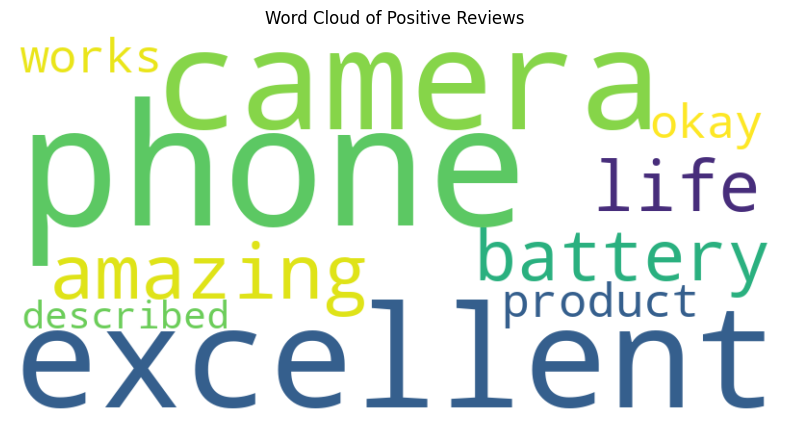

In [6]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Three product reviews
reviews = [
    "This phone has an excellent camera and amazing battery life.",
    "The laptop is very slow and the battery is disappointing.",
    "The product is okay and works as described."
]

positive_reviews = []

# 1. Calculate polarity and subjectivity
# 2. Classify reviews
for i, review in enumerate(reviews, start=1):
    blob = TextBlob(review)

    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0.1:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print(f"\nReview {i}: {review}")
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)

# 3. Create a word cloud for positive reviews
if positive_reviews:
    positive_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(positive_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()
else:
    print("No positive reviews found.")

In [7]:
import numpy as np
import nltk
from nltk.tokenize import word_tokenize
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

nltk.download('punkt')
nltk.download('punkt_tab')

# 1. Training paragraph (approximately 100 words)
text = """
Technology has changed the way people live and work.
Computers help people solve problems and process information.
Artificial intelligence allows machines to learn from data.
Machine learning helps computers recognize patterns and make predictions.
Students use technology to learn new skills and explore ideas.
Teachers use digital tools to explain difficult concepts.
Technology also improves communication between people.
The internet provides access to information from around the world.
Mobile applications help people manage their daily activities.
Robots can perform repetitive tasks quickly and accurately.
However, technology should be used responsibly.
People must protect their privacy and personal information.
Learning programming develops logical thinking and creativity.
Technology continues to create new opportunities for innovation.
The future will depend on how wisely people use these tools.
"""

# 2. Tokenize text using Keras Tokenizer
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1
sequences = []

# Create progressively longer input sequences
for line in text.strip().split('\n'):
    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(token_list)):
        sequences.append(token_list[:i + 1])

# Pad sequences to equal length
max_sequence_len = max(len(seq) for seq in sequences)
sequences = pad_sequences(
    sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

# Input = all words except last
# Output = next word
X = sequences[:, :-1]
y = sequences[:, -1]

# 3. Build a simple LSTM model
model = Sequential([
    Embedding(
        input_dim=total_words,
        output_dim=32,
        input_length=max_sequence_len - 1
    ),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# Train the model
model.fit(X, y, epochs=100, verbose=0)

print("Model training completed.")

# 4. Generate text from a seed word
def generate_text(seed_text, next_words=10):
    result = seed_text

    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([result])[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding='pre'
        )

        predicted = model.predict(token_list, verbose=0)
        predicted_index = np.argmax(predicted, axis=1)[0]

        if predicted_index == 0:
            break

        output_word = tokenizer.index_word.get(predicted_index)

        if output_word is None:
            break

        result += " " + output_word

    return result

# Generate 2–3 lines from a seed word
seed = "technology"

print("\nGenerated Text:")
print(generate_text(seed, 10))
print(generate_text(seed, 10))
print(generate_text(seed, 10))

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model training completed.

Generated Text:
technology technology to to learn new from around world world world
technology technology to to learn new from around world world world
technology technology to to learn new from around world world world
